In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)




GAUSSIAN NAIVE BAYES: PURCHASE PREDICTION

First five rows:
   User ID  Gender  Age  EstimatedSalary  Purchased
0        1    Male   45            76908          0
1        2  Female   43            82876          0
2        3  Female   32            74611          0
3        4  Female   64            54501          1
4        5  Female   48            51254          0

Dataset shape: (10000, 5)

Missing values:
User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

Purchase distribution:
Purchased
0    6376
1    3624
Name: count, dtype: int64

Training records: 7500
Testing records : 2500

QUESTION 1: AGE + ESTIMATED SALARY

Accuracy : 0.7572
Precision: 0.7582
Recall   : 0.4845
F1-Score : 0.5912

Confusion Matrix:
[[1454  140]
 [ 467  439]]

Classification Report:
                   precision    recall  f1-score   support

Not Purchased (0)       0.76      0.91      0.83      1594
    Purchased (1)       0.76      0.48   

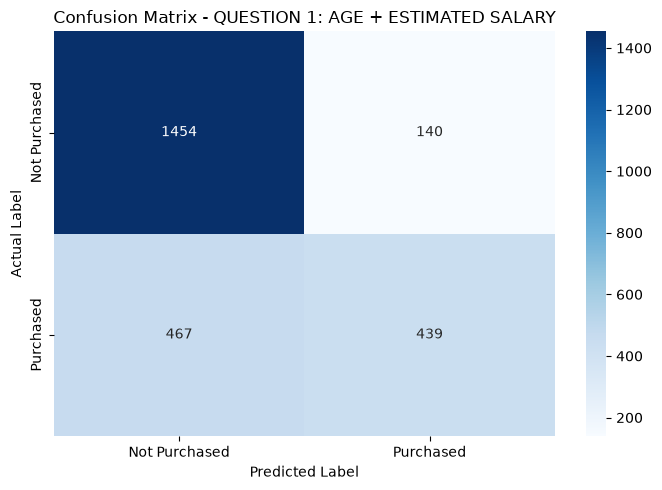


QUESTION 2: GENDER + AGE + ESTIMATED SALARY

Accuracy : 0.7588
Precision: 0.7608
Recall   : 0.4879
F1-Score : 0.5945

Confusion Matrix:
[[1455  139]
 [ 464  442]]

Classification Report:
                   precision    recall  f1-score   support

Not Purchased (0)       0.76      0.91      0.83      1594
    Purchased (1)       0.76      0.49      0.59       906

         accuracy                           0.76      2500
        macro avg       0.76      0.70      0.71      2500
     weighted avg       0.76      0.76      0.74      2500



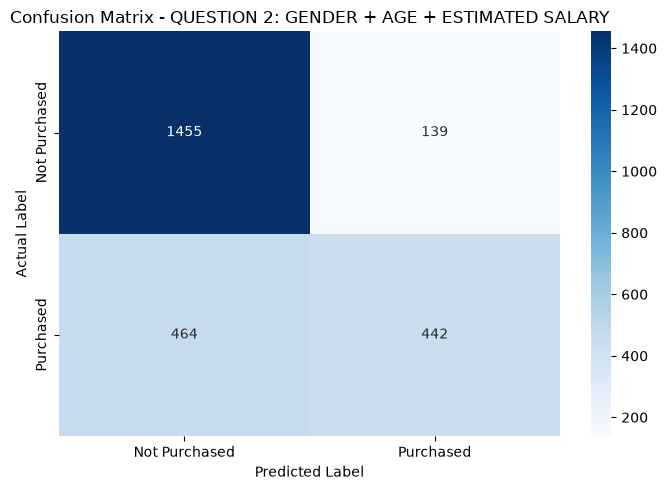


COMPARISON OF QUESTION 1 AND QUESTION 2
                                   Question  Accuracy  Precision   Recall  F1-Score
         QUESTION 1: AGE + ESTIMATED SALARY    0.7572   0.758204 0.484547  0.591246
QUESTION 2: GENDER + AGE + ESTIMATED SALARY    0.7588   0.760757 0.487859  0.594486

Conclusion:
Adding Gender improved the accuracy on this test split.
Compare Precision, Recall and F1-Score as well. Accuracy alone does not describe every aspect of classification performance.

Generated files:
1. q1_confusion_matrix.png
2. q2_confusion_matrix.png
3. naive_bayes_model_comparison.csv

Program completed successfully.


In [2]:


# ---------------------------------------------------------
# 1. LOAD AND EXPLORE DATA
# ---------------------------------------------------------
df = pd.read_csv("purchase_logistic.csv")

print("=" * 70)
print("GAUSSIAN NAIVE BAYES: PURCHASE PREDICTION")
print("=" * 70)

print("\nFirst five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nPurchase distribution:")
print(df["Purchased"].value_counts())


# ---------------------------------------------------------
# 2. DATA CLEANING
# ---------------------------------------------------------
# Remove duplicate rows.
df = df.drop_duplicates()

# Remove records where the target is missing.
df = df.dropna(subset=["Purchased"]).copy()

# Fill missing numerical values with their median.
for column in ["Age", "EstimatedSalary"]:
    df[column] = df[column].fillna(df[column].median())

# Fill missing Gender values with the most frequent category.
df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])

# Encode Gender: Female/Male become numeric labels.
gender_encoder = LabelEncoder()
df["Gender"] = gender_encoder.fit_transform(df["Gender"].astype(str))

# User ID is only an identifier, so it is not used as a feature.
# Purchased is the target column: 0 = No, 1 = Yes.
y = df["Purchased"].astype(int)


# ---------------------------------------------------------
# 3. COMMON TRAIN-TEST SPLIT
# ---------------------------------------------------------
# Use the same split for both questions for a fair comparison.
train_indices, test_indices = train_test_split(
    df.index,
    test_size=0.25,
    random_state=42,
    stratify=y
)

y_train = y.loc[train_indices]
y_test = y.loc[test_indices]

print("\nTraining records:", len(train_indices))
print("Testing records :", len(test_indices))


# ---------------------------------------------------------
# 4. FUNCTION TO TRAIN GAUSSIAN NAIVE BAYES
# ---------------------------------------------------------
def train_and_evaluate(feature_columns, question_name, plot_file):
    print("\n" + "=" * 70)
    print(question_name)
    print("=" * 70)

    X = df[feature_columns]

    X_train = X.loc[train_indices]
    X_test = X.loc[test_indices]

    # StandardScaler is fitted only on training data.
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Train Gaussian Naive Bayes classifier.
    classifier = GaussianNB()
    classifier.fit(X_train_scaled, y_train)

    # Predict the purchase result.
    y_pred = classifier.predict(X_test_scaled)

    # Calculate classification metrics.
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    print("\nAccuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1-Score :", round(f1, 4))

    # Print confusion matrix.
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    print("\nConfusion Matrix:")
    print(cm)

    # Print classification report.
    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["Not Purchased (0)", "Purchased (1)"],
            zero_division=0
        )
    )

    # Plot confusion matrix.
    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not Purchased", "Purchased"],
        yticklabels=["Not Purchased", "Purchased"]
    )
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.title(f"Confusion Matrix - {question_name}")
    plt.tight_layout()
    plt.savefig(plot_file, dpi=300)
    plt.show()

    return {
        "Question": question_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }


# ---------------------------------------------------------
# 5. QUESTION 1
# Features: Age and EstimatedSalary
# ---------------------------------------------------------
q1_result = train_and_evaluate(
    feature_columns=["Age", "EstimatedSalary"],
    question_name="QUESTION 1: AGE + ESTIMATED SALARY",
    plot_file="q1_confusion_matrix.png"
)


# ---------------------------------------------------------
# 6. QUESTION 2
# Features: Gender, Age and EstimatedSalary
# ---------------------------------------------------------
q2_result = train_and_evaluate(
    feature_columns=["Gender", "Age", "EstimatedSalary"],
    question_name="QUESTION 2: GENDER + AGE + ESTIMATED SALARY",
    plot_file="q2_confusion_matrix.png"
)


# ---------------------------------------------------------
# 7. COMPARE BOTH MODELS
# ---------------------------------------------------------
comparison = pd.DataFrame([q1_result, q2_result])

print("\n" + "=" * 70)
print("COMPARISON OF QUESTION 1 AND QUESTION 2")
print("=" * 70)
print(comparison.to_string(index=False))

comparison.to_csv("naive_bayes_model_comparison.csv", index=False)

print("\nConclusion:")
if q2_result["Accuracy"] > q1_result["Accuracy"]:
    print("Adding Gender improved the accuracy on this test split.")
elif q2_result["Accuracy"] < q1_result["Accuracy"]:
    print("Adding Gender reduced the accuracy on this test split.")
else:
    print("Both models achieved the same accuracy on this test split.")

print(
    "Compare Precision, Recall and F1-Score as well. "
    "Accuracy alone does not describe every aspect of classification performance."
)

print("\nGenerated files:")
print("1. q1_confusion_matrix.png")
print("2. q2_confusion_matrix.png")
print("3. naive_bayes_model_comparison.csv")
print("\nProgram completed successfully.")
